# Modelo en producción: degradación del desempeño

Cada mes se etiquetan manualmente 100 registros. Con esas muestras vemos cómo evolucionan la *accuracy* y el F1 macro respecto de la evaluación en test. Antes de proponer hipótesis, conviene preguntar **qué parte de la caída es real y qué parte es ruido de muestreo**: 100 registros son pocos.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
def validation_gate(condicion: bool, mensaje: str) -> None:
    """Puerta de validación: detiene el notebook si un supuesto no se cumple."""
    if not condicion:
        raise AssertionError(f"validation_gate FALLIDO: {mensaje}")
    print(f"OK  {mensaje}")

In [3]:
production_metrics = pd.DataFrame(
    {
        "periodo": ["Testing", "Mes 3", "Mes 6", "Mes 10"],
        "mes": [0, 3, 6, 10],
        "n": [3927, 100, 100, 100],  # test de la parte 1: 3.927 registros
        "accuracy": [0.938, 0.923, 0.913, 0.83],
        "f1_macro": [0.823, 0.812, 0.796, 0.71],
    }
).set_index("periodo")

validation_gate(
    production_metrics[["accuracy", "f1_macro"]].stack().between(0, 1).all(),
    "las métricas están en [0, 1]",
)
validation_gate(
    production_metrics["mes"].is_monotonic_increasing, "los periodos están en orden cronológico"
)
validation_gate(
    (production_metrics["accuracy"] >= production_metrics["f1_macro"]).all(),
    "accuracy >= F1 macro en todos los periodos (coherente con clases desbalanceadas)",
)

OK  las métricas están en [0, 1]
OK  los periodos están en orden cronológico
OK  accuracy >= F1 macro en todos los periodos (coherente con clases desbalanceadas)


## 1. ¿Es significativa la caída?

Calculamos un intervalo de confianza del 95% para la *accuracy* de cada mes. Usamos el intervalo de Wilson, que se comporta bien con proporciones cercanas a 1 y muestras pequeñas. Con n = 100, el error estándar de una *accuracy* de 0,92 es cercano a ±2,7 puntos.

In [4]:
from statsmodels.stats.proportion import proportion_confint

# statsmodels trabaja con conteos: aciertos = accuracy * n (100 registros -> 83 aciertos en el mes 10)
aciertos = (production_metrics["accuracy"] * production_metrics["n"]).round().astype(int)
ic_inf, ic_sup = proportion_confint(
    count=aciertos, nobs=production_metrics["n"], alpha=0.05, method="wilson"
)
production_metrics["acc_ic_inf"] = ic_inf
production_metrics["acc_ic_sup"] = ic_sup

validation_gate(
    (production_metrics["acc_ic_inf"] <= production_metrics["accuracy"]).all()
    and (production_metrics["accuracy"] <= production_metrics["acc_ic_sup"]).all(),
    "cada accuracy queda dentro de su propio intervalo de confianza",
)

production_metrics["caida_acc_vs_test"] = (
    production_metrics["accuracy"] - production_metrics.loc["Testing", "accuracy"]
)
production_metrics["brecha_acc_f1"] = (
    production_metrics["accuracy"] - production_metrics["f1_macro"]
)
production_metrics["test_dentro_del_ic"] = (
    production_metrics.loc["Testing", "accuracy"] <= production_metrics["acc_ic_sup"]
)
production_metrics.round(3)

OK  cada accuracy queda dentro de su propio intervalo de confianza


,mes,n,accuracy,f1_macro,acc_ic_inf,acc_ic_sup,caida_acc_vs_test,brecha_acc_f1,test_dentro_del_ic
periodo,,,,,,,,,
Testing,0,3927,0.938,0.823,0.930,0.945,0.000,0.115,True
Mes 3,3,100,0.923,0.812,0.850,0.959,-0.015,0.111,True
Mes 6,6,100,0.913,0.796,0.838,0.952,-0.025,0.117,True
Mes 10,10,100,0.830,0.710,0.745,0.891,-0.108,0.120,False


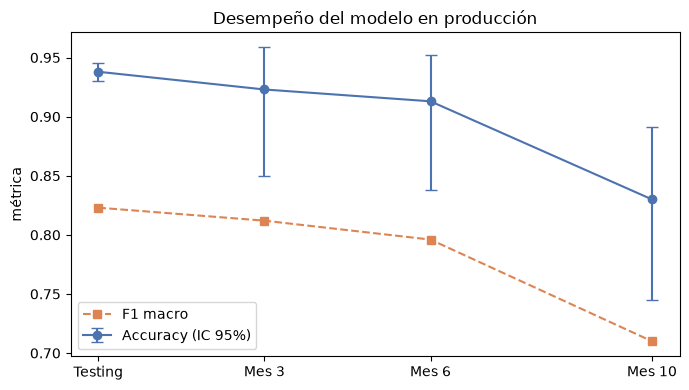

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))

err = [
    production_metrics["accuracy"] - production_metrics["acc_ic_inf"],
    production_metrics["acc_ic_sup"] - production_metrics["accuracy"],
]

ax.errorbar(
    production_metrics["mes"],
    production_metrics["accuracy"],
    yerr=err,
    fmt="o-",
    capsize=4,
    label="Accuracy (IC 95%)",
    color="#4C72B0",
)

ax.plot(
    production_metrics["mes"],
    production_metrics["f1_macro"],
    "s--",
    label="F1 macro",
    color="#DD8452",
)

ax.set_xticks(production_metrics["mes"], production_metrics.index)
ax.set_ylabel("métrica")
ax.set_title("Desempeño del modelo en producción")
ax.legend()
plt.tight_layout()

**Lectura:**

- **Meses 3 y 6:** la *accuracy* de test (0,938) cae dentro del intervalo de confianza de ambos meses. Con 100 registros **no podemos afirmar que el modelo se haya degradado**. La tendencia a la baja es consistente, pero podría ser ruido.
- **Mes 10:** la caída es de unos 11 puntos y el intervalo superior queda por debajo de 0,938. Este cambio **sí es real**.
- **Brecha *accuracy* − F1 macro:** se mantiene en torno a 0,11-0,12 en todos los periodos. El F1 macro no cae más rápido que la *accuracy*, así que el deterioro no parece concentrado solo en las clases raras: afecta de forma más general. Hay que tomarlo con cautela, porque con 100 registros y 79 clases muchas clases no aparecen en la muestra y el F1 macro mensual es muy inestable.

## 2. Hipótesis

Ordenadas desde lo más fácil de descartar hasta lo más probable de fondo:

1. **Un problema técnico en el *pipeline*.** El salto brusco entre el mes 6 y el 10 podría deberse a un cambio en cómo llegan los datos y no a la población: otra codificación de caracteres, campos truncados o intercambiados, o un cambio en el formulario de captura. Es la hipótesis más barata de verificar, así que va primero.
2. **Cambio en la población (*data drift*).** El lenguaje y la composición de los empleos cambian: aparecen ocupaciones nuevas (por ejemplo, *delivery* por aplicación), nuevas formas de describir las tareas, o cambia el peso de cada sector. Si el modelo es más débil en los sectores que crecen, la *accuracy* global baja aunque cada clase se prediga igual que antes.
3. **Estacionalidad.** En Chile, buena parte del empleo agrícola y agroindustrial es temporal. Si el mes 10 coincide con otra temporada, cambia la mezcla de actividades (por ejemplo, más temporeros o empleos de comercio en fechas específicas). Para comprobarlo hay que comparar con el mismo mes del año anterior.
4. **Cambio en el concepto o en el etiquetado (*concept drift*).** Puede haber cambiado el criterio para asignar el código: una actualización del manual de codificación, un clasificador nuevo o codificadores nuevos con otro criterio. En ese caso el mismo texto recibe hoy otra etiqueta, y el modelo "falla" aunque haga lo mismo que antes.
5. **Ruido de muestreo**, solo para los meses 3 y 6, como mostró la sección anterior.

## 3. Estrategia de mitigación (sin implementar)

**a) Diagnosticar antes de reentrenar.** Reentrenar a ciegas puede esconder un problema técnico o, si el cambio fue de criterio, aprender etiquetas inconsistentes.

- Revisar el *pipeline* de ingesta del mes 10: esquema, largos de texto, caracteres extraños, campos vacíos.
- Comparar el mes 10 contra train **sin necesitar etiquetas**: distribución de largos, proporción de palabras nunca vistas, distribución de la confianza del modelo y distribución de clases predichas. Un aumento de casos de baja confianza o de vocabulario nuevo apunta a *data drift*.
- Revisar manualmente los errores del mes 10, para ver si son casos nuevos (*drift*) o casos conocidos con otra etiqueta (cambio de criterio).
- Consultar al equipo de codificación si hubo cambios en el manual, el formulario o el personal.

**b) Contener el impacto mientras se corrige.** Bajar el umbral de confianza para que más registros pasen a revisión humana. Así se protege la calidad del dato publicado a cambio de más trabajo manual, y se ganan etiquetas nuevas.

**c) Corregir según la causa:**

- Si es un problema técnico, se arregla el *pipeline*. No hace falta reentrenar.
- Si es *drift* o estacionalidad, se reentrena incorporando los datos recientes etiquetados, quizás con más peso para lo reciente, y se eligen los registros a etiquetar priorizando los de baja confianza (aprendizaje activo).
- Si cambió el criterio, se reetiqueta una muestra histórica con el criterio nuevo antes de reentrenar.

Cualquier modelo nuevo se compara contra el actual (*champion/challenger*) sobre los mismos datos recientes antes de reemplazarlo.

**d) Monitoreo permanente.**

- **Muestras mensuales más informativas.** Con 100 registros solo se detectan caídas grandes. Conviene aumentar el tamaño de la muestra o estratificarla (por sector o por nivel de confianza) para detectar antes las caídas moderadas.
- **Alertas automáticas sin etiquetas** (confianza media, vocabulario nuevo, distribución de clases predichas), que avisen antes de tener las etiquetas manuales.
- **Una política de reentrenamiento periódica** que no dependa de esperar a que la métrica se desplome.